# 28 · Write and test a custom model

What does a nearest-neighbour forecast learn from its history? Write a k-nearest-analogues model, compare it with known synthetic truth, then use it on real observations and a semi-synthetic series with a supplied truth function.

The 2021 KNN figure put a truth line beside observed and predicted points. Here the current plotting helpers bring that comparison back: gray observation dots, blue prediction crosses, a thin known-mean curve, and a marked forecast origin. This model uses whole historical continuations; it is not a reconstruction of the original recursive KNN implementation.

## Run this notebook

From the repository root, install `python -m pip install -e '.[notebooks]'`, then launch `python -m jupyterlab notebooks`. Use that Python kernel and run all cells in order. See the [notebook guide](README.md). All data are local. The controlled suite uses three scenarios and two seeds; no model is downloaded or tuned on its holdout.

In [1]:
from pathlib import Path
import hashlib
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

import timegym
from timegym import Pipeline, Scenario, Forecast, ForecastTask, Reference, Case
from timegym.contracts import DEFAULT_LEVELS
from timegym.diagnostics import evaluate_forecast
from timegym.evaluation import EvaluatedCase, ForecastRun

%matplotlib inline
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "pyproject.toml").is_file() and (p / "timegym").is_dir())
plt.rcParams.update({"figure.figsize": (12, 4), "figure.dpi": 110, "font.size": 11,
                     "figure.facecolor": "white", "axes.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False,
                     "axes.grid": False, "legend.frameon": False, "axes.titlelocation": "left"})
print(f"TimeGym {timegym.__version__} | NumPy {np.__version__} | pandas {pd.__version__}")

TimeGym 1.1.0 | NumPy 2.5.4 | pandas 3.1.1


## 1 · Write the model and see its forecast

`fit(context)` stores only the observed prefix. At prediction time, compare the latest `window_length` rows with every historical window whose **entire H-step continuation is already in context**. Select the `k` smallest squared distances, then return the mean of their continuations as `(H, D)` points.

The same `k` continuations form `(k, H, D)` empirical paths. Keep each continuation intact across horizons and targets. Their empirical quantiles are `(H, D, Q)` marginal summaries. Neighbours can overlap and are selected from one history: they are not independent draws from the true conditional law, and these intervals have no nominal-coverage guarantee.

Distances use raw values, without detrending, rescaling, or level alignment. This makes the model's inability to extrapolate a rising level visible. `clone_unfitted()` lets `Pipeline` start each case afresh; `params()` records the notebook model's settings.

In [2]:
from numbers import Integral


class NearestAnalogues:
    def __init__(self, *, window_length=12, k=8):
        for name, value in {"window_length": window_length, "k": k}.items():
            if isinstance(value, bool) or not isinstance(value, Integral) or value < 1:
                raise ValueError(f"{name} must be a positive integer")
        self.window_length = int(window_length)
        self.k = int(k)

    def params(self):
        return {"window_length": self.window_length, "k": self.k}

    def clone_unfitted(self):
        return type(self)(**self.params())

    def fit(self, context):
        if not isinstance(context, pd.DataFrame):
            raise TypeError("context must be a pandas DataFrame")
        self.context_ = context.copy(deep=True)
        return self

    def predict(self, future_index):
        if not hasattr(self, "context_"):
            raise RuntimeError("Call fit(context) before predict(future_index)")
        task = ForecastTask(self.context_, future_index)
        values = task.context.to_numpy(dtype=float)
        window, horizon = self.window_length, len(future_index)
        count = len(values) - window - horizon + 1
        if count < self.k:
            raise ValueError(
                f"Need at least window_length + horizon + k - 1 context rows; "
                f"got {len(values)} for window_length={window}, horizon={horizon}, k={self.k}"
            )
        windows = np.stack([values[start:start + window] for start in range(count)])
        distances = np.mean((windows - values[-window:]) ** 2, axis=(1, 2))
        self.neighbor_starts_ = np.argsort(distances, kind="stable")[:self.k]
        paths = np.stack([values[start + window:start + window + horizon]
                          for start in self.neighbor_starts_])
        return Forecast(
            index=future_index.copy(), point=paths.mean(axis=0), samples=paths,
            quantiles=np.quantile(paths, DEFAULT_LEVELS, axis=0).transpose(1, 2, 0),
            levels=DEFAULT_LEVELS, target_names=task.target_names,
        )

In [3]:
example = Scenario("seasonal", context_length=240, horizon=36,
                   parameters={"mean": 2.0, "amplitude": 1.0, "period": 24.0, "sigma": 0.15})
case = example.generate(seed=7)
model = NearestAnalogues(window_length=12, k=8).fit(case.task.context)
forecast = model.predict(case.task.future_index)
assert forecast.validate(case.task) == []
assert forecast.samples.shape == (8, 36, 1)
np.testing.assert_allclose(forecast.point, forecast.samples.mean(axis=0))

starts = model.neighbor_starts_
ends = starts + model.window_length + len(case.task.future_index)
assert np.all(ends <= len(case.task.context))
display(pd.DataFrame({"window_start": starts,
                      "continuation_start": starts + model.window_length,
                      "continuation_stop_exclusive": ends,
                      "context_stop_exclusive": len(case.task.context)}))

,window_start,continuation_start,continuation_stop_exclusive,context_stop_exclusive
0,108,120,156,240
1,132,144,180,240
2,156,168,204,240
3,180,192,228,240
4,60,72,108,240
5,84,96,132,240
6,36,48,84,240
7,83,95,131,240


### Where are the predicted points?

The reference knows the generating seasonal mean. The model sees only the gray context dots. The blue crosses below average the selected paths; they are not a connected future trajectory. The band joins marginal 10th and 90th percentiles of eight analogues, not an 80% simultaneous region.

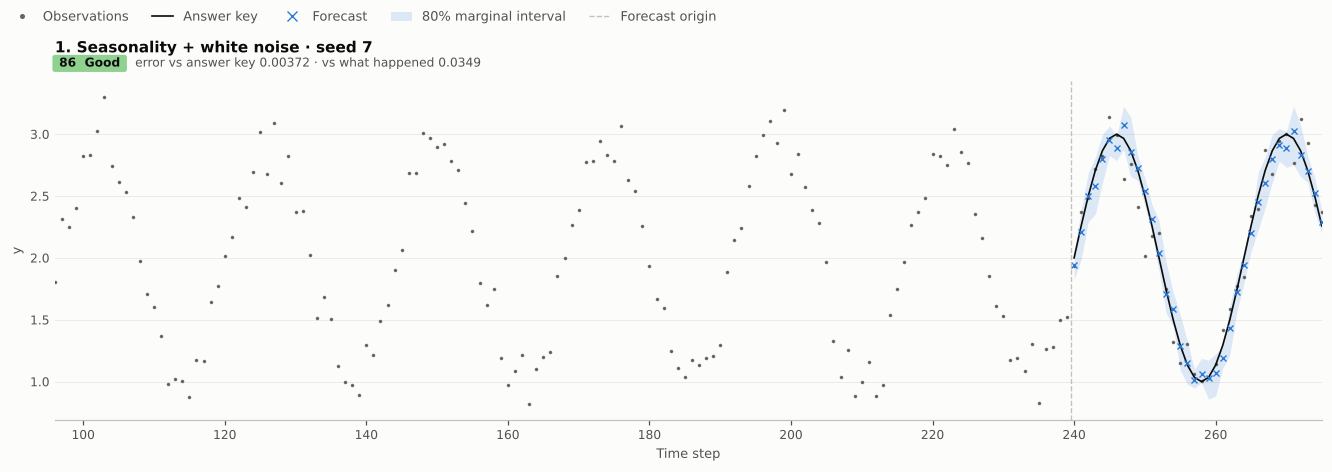

mse                          0.034912
mae                          0.145783
mase                         0.666658
mean_reference_mse           0.003717
pinball                      0.048057
interval_coverage            0.666667
interval_nominal_coverage    0.800000
interval_width               0.317404
crps                         0.107773
energy_score                 0.844797
variogram_score              0.027510
Name: One-case descriptive losses, dtype: float64

In [4]:
result = evaluate_forecast(case, forecast)
example_run = ForecastRun([EvaluatedCase(case, forecast, result, 0, 0)])
fig = example_run.plot_forecasts(show_quantiles=True, figsize=(12, 4.2))
plt.show()

display(pd.Series(result.metrics, name="One-case descriptive losses"))

A repeating pattern supplies similar past windows. Their continuations can track the reference, while observation noise keeps the held-out dots away from that mean. Observed MSE and mean-reference MSE answer different questions; a good fit on this one realization establishes neither calibration nor general forecasting skill.

## 2 · Test the same model on known scenarios

`Pipeline.test` clones and refits the model for every scenario and seed. White noise tests averaging, a linear trend tests extrapolation, and seasonality tests repetition. Each reference is known by construction. A `PASS` for `forecast_contract` checks shape, finiteness, indexes, and target order. Point accuracy remains `INCONCLUSIVE` because no acceptance tolerance is declared.

The six cases are a small demonstration. The two independent seeds within each scenario are replications; neither the forecast horizons nor the eight overlapping analogues supply extra independent cases.

In [5]:
pipeline = Pipeline(NearestAnalogues(window_length=12, k=8))
suite = [
    Scenario("white_noise", context_length=240, horizon=36,
             parameters={"mean": 2.0, "sigma": 0.5}),
    Scenario("trend", context_length=240, horizon=36,
             parameters={"intercept": 0.0, "slope": 0.02, "sigma": 0.15}),
    example,
]
seeds = [7, 19]
test_report = pipeline.test(suite, seeds=seeds)
assert len(test_report.cases) == 6
assert all(any(d.name == "forecast_contract" and d.status == "PASS"
               for d in result.diagnostics) for result in test_report.cases)
assert not any(d.status in {"FAIL", "ERROR"}
               for result in test_report.cases for d in result.diagnostics)
display(pd.DataFrame([{"scenario": r.scenario, "seed": r.seed,
                       "observed_MSE": r.metrics["mse"],
                       "mean_reference_MSE": r.metrics["mean_reference_mse"],
                       "contract": next(d.status for d in r.diagnostics if d.name == "forecast_contract"),
                       "point_accuracy": next(d.status for d in r.diagnostics if d.name == "point_accuracy")}
                      for r in test_report.cases]).round(4))

,scenario,seed,observed_MSE,mean_reference_MSE,contract,point_accuracy
0,white_noise,7,0.3210,0.0325,PASS,INCONCLUSIVE
1,white_noise,19,0.2293,0.0195,PASS,INCONCLUSIVE
2,trend,7,0.6696,0.6800,PASS,INCONCLUSIVE
3,trend,19,0.6741,0.6395,PASS,INCONCLUSIVE
4,seasonal,7,0.0349,0.0037,PASS,INCONCLUSIVE
5,seasonal,19,0.0211,0.0037,PASS,INCONCLUSIVE


### Bring the KNN comparison back

`test` returns a serializable report. To retain the arrays for plots, use `run` and read its `.report`. Here the second call deliberately refits the same deterministic model on the same seeds; we check that its case results match `test`. Subsequent plots reuse this retained run without refitting.

The known-mean curve is drawn only over the held-out horizon, where it serves as the evaluation reference. Contract status is added to each panel; the plotting helper supplies observations, predictions, reference curves, scores, and failure annotations.

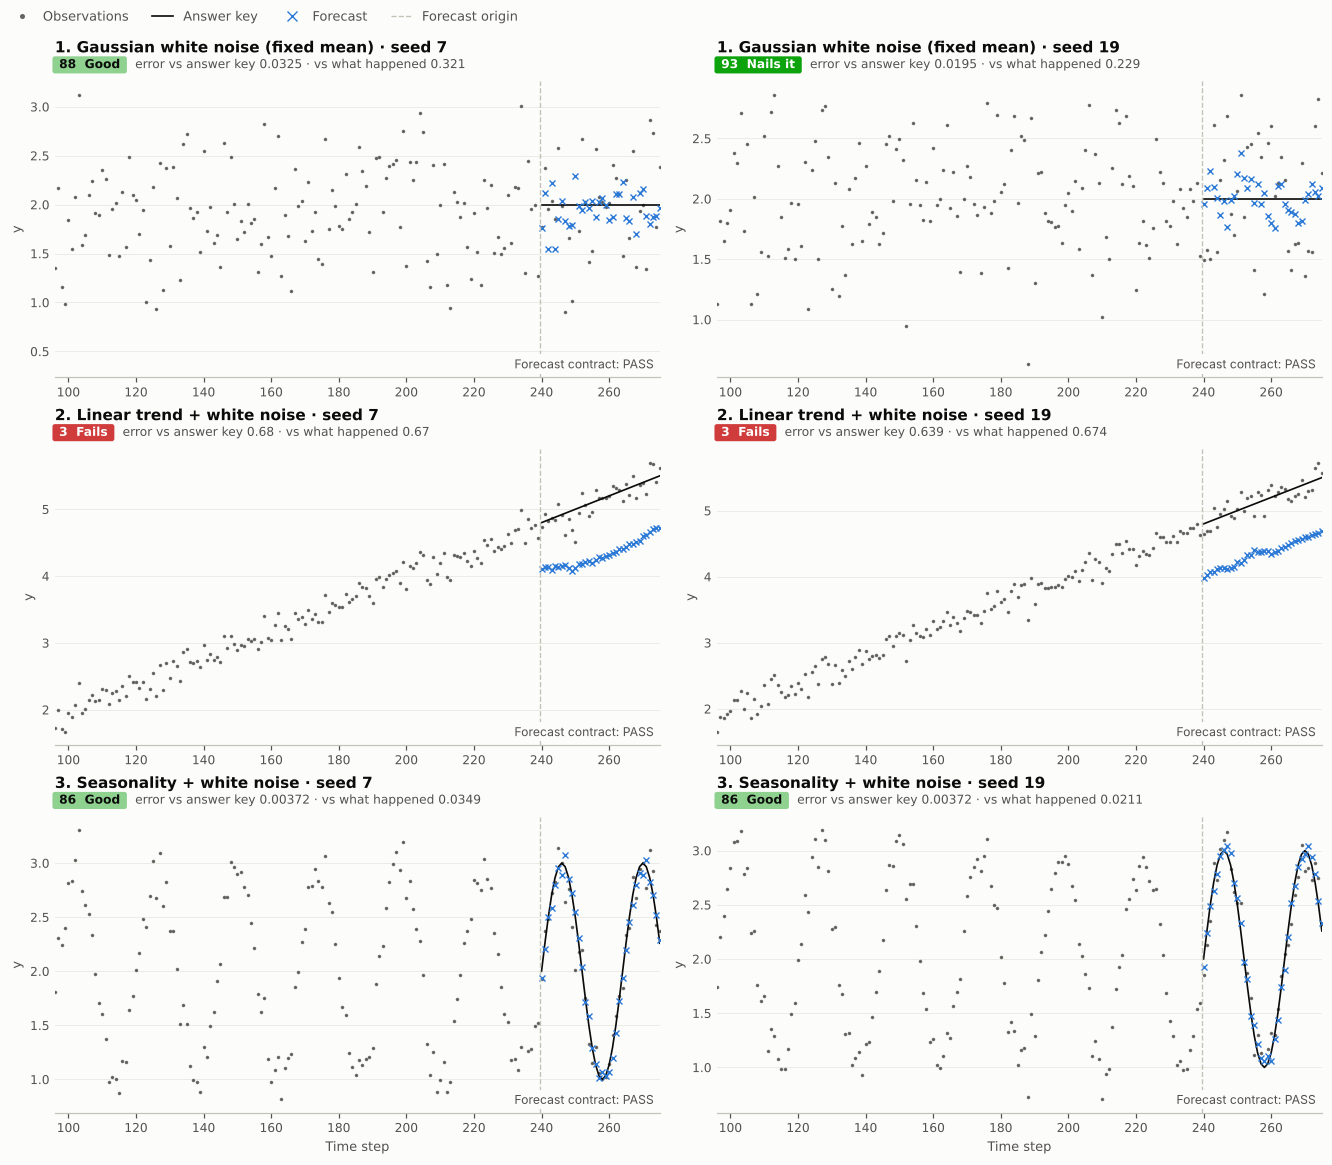

In [6]:
retained = pipeline.run(suite, seeds=seeds)
assert [r.to_dict() for r in test_report.cases] == [r.to_dict() for r in retained.report.cases]


def plot_contracts(run, *, figsize):
    fig = run.plot_forecasts(figsize=figsize)
    for ax, entry in zip(fig.axes, run.cases):
        contract = next(d.status for d in entry.result.diagnostics if d.name == "forecast_contract" or d.name.startswith("contract_"))
        ax.text(0.99, 0.02, f"Forecast contract: {contract}", transform=ax.transAxes,
                ha="right", va="bottom", fontsize=8, color="#52514e",
                bbox={"facecolor": "#fcfcfb", "edgecolor": "none", "pad": 1.5})
    return fig


fig = plot_contracts(retained, figsize=(12, 10.5))
asset_path = ROOT / "notebooks" / "assets" / "custom-model-knn.png"
asset_path.parent.mkdir(parents=True, exist_ok=True)
fig.savefig(asset_path, dpi=150, bbox_inches="tight")
plt.show()

The trend panel exposes a limitation even while its contract passes: averaging historical continuations cannot extrapolate beyond their range. The seasonal panels ask whether an appropriate pattern recurs in context. The noise panels ask how well eight selected continuations estimate a fixed mean. These are properties of this model and these controlled processes, not a ranking on real forecasting tasks.

### Make a contract failure visible

A forecast can be inaccurate yet structurally valid. To demonstrate a genuine `FAIL`, inject a different problem: drop the final point row while keeping the requested index. This is an output-shape fault, not evidence that nearest neighbours always fail. The same plotting helper withholds malformed predictions and explains the contract violation.

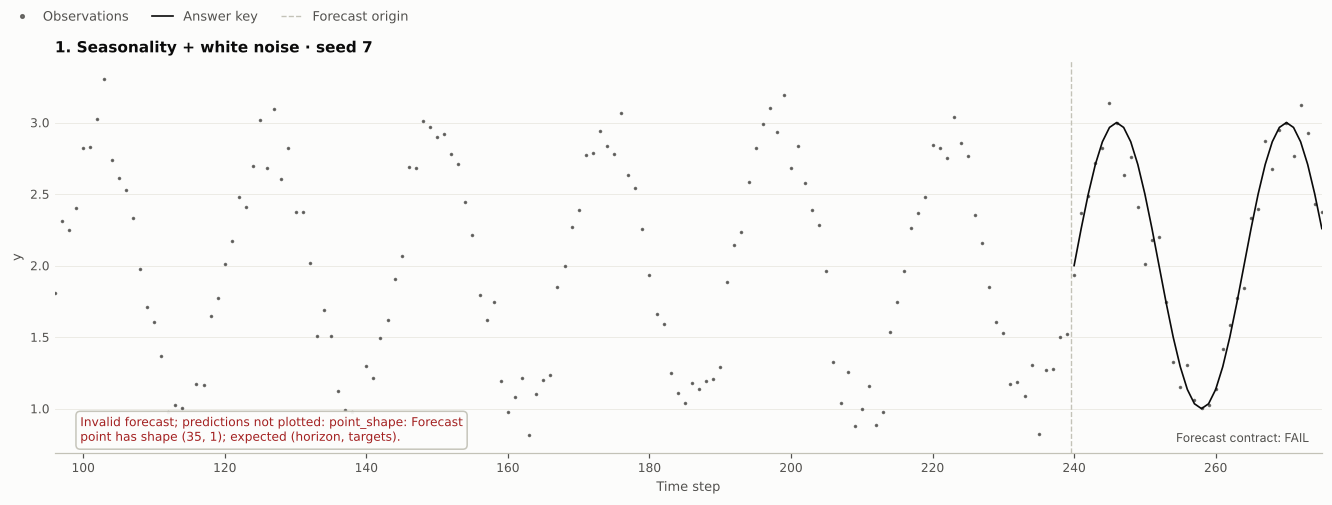

,check,status,message
0,contract_point_shape,FAIL,"Forecast point has shape (35, 1); expected (ho..."


In [7]:
class MissingLastPoint(NearestAnalogues):
    def predict(self, future_index):
        prediction = super().predict(future_index)
        prediction.point = prediction.point[:-1]
        return prediction


broken_pipeline = Pipeline(MissingLastPoint(window_length=12, k=8))
broken_report = broken_pipeline.test([example], seeds=[7])
assert any(d.name == "contract_point_shape" and d.status == "FAIL"
           for d in broken_report.cases[0].diagnostics)
broken_run = broken_pipeline.run([example], seeds=[7])
assert broken_run.report.cases[0].to_dict() == broken_report.cases[0].to_dict()
fig = plot_contracts(broken_run, figsize=(12, 4.5))
plt.show()
display(pd.DataFrame([{"check": d.name, "status": d.status, "message": d.message}
                      for d in broken_report.cases[0].diagnostics]))

## 3 · Use real observations, then supply known truth

First hold out the final 12 months of the bundled AirPassengers series. It contains monthly passenger counts in thousands; the [data record](../experiments/data/README.md) gives its source and checksum. The model receives the preceding 132 months only. No true conditional mean or covariance is available for these historical observations.

Keep only the model's point output for this comparison. Observed losses are descriptive; missing uncertainty outputs and the requested reference-covariance comparison remain `UNSUPPORTED`. An unavailable reference score is omitted, not replaced by zero.

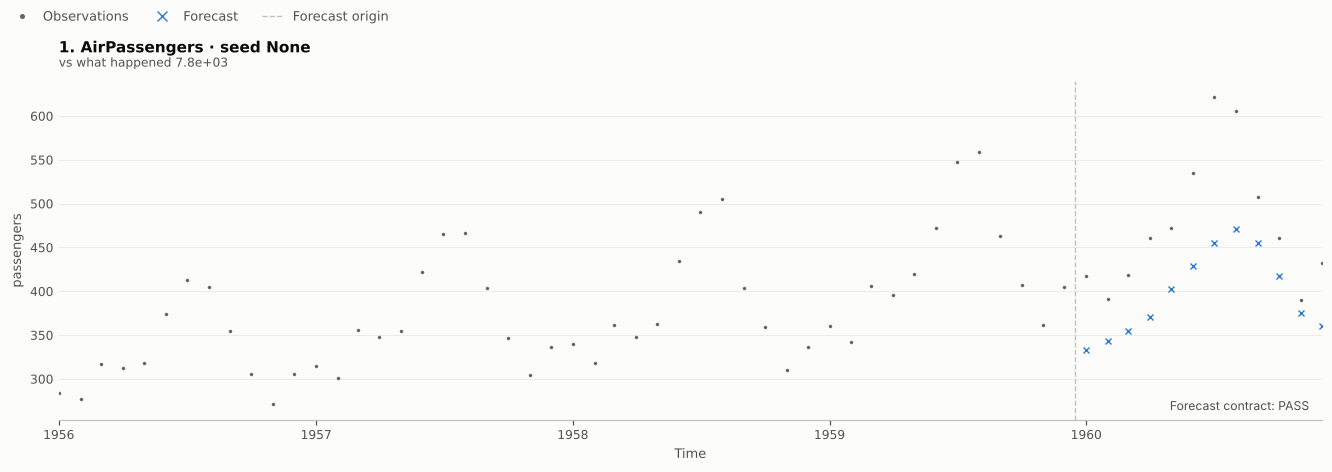

,check,status,message
0,forecast_contract,PASS,"Forecast indices, target order, shapes, finite..."
1,point_accuracy,INCONCLUSIVE,Point scores are descriptive; no capability ac...
2,quantile_accuracy,UNSUPPORTED,No explicit quantile forecasts were supplied.
3,sample_scores,UNSUPPORTED,No joint predictive samples were supplied.
4,reference_covariance,UNSUPPORTED,Predictive samples and a reference covariance ...


mse     7801.949219
mae       78.781250
mase       3.271107
Name: Real-data descriptive losses, dtype: float64

In [8]:
data_path = ROOT / "experiments" / "data" / "AirPassengers.csv"
source_sha256 = hashlib.sha256(data_path.read_bytes()).hexdigest()
assert source_sha256 == "bdb98adbd418a6de6842a742e0602f363c3b841c26677e7e61a1e055e9509bd8"
raw = pd.read_csv(data_path)
series = pd.DataFrame({"passengers": raw["value"].to_numpy(dtype=float)},
                      index=pd.period_range("1949-01", periods=len(raw), freq="M"))
origin = 132
real_task = ForecastTask(series.iloc[:origin].copy(), series.index[origin:].copy())
real_case = Case(real_task, series.iloc[origin:].copy(), reference=None,
                 manifest={"kind": "AirPassengers", "seed": None,
                           "context_length": origin, "horizon": len(real_task.future_index),
                           "source_sha256": source_sha256})


def point_prediction(task):
    prediction = pipeline.predict(task.context, task.future_index)
    return Forecast(index=prediction.index, point=prediction.point,
                    target_names=prediction.target_names)


real_forecast = point_prediction(real_task)
real_result = evaluate_forecast(real_case, real_forecast, check_dependence=True)
assert real_forecast.validate(real_task) == []
assert "mean_reference_mse" not in real_result.metrics
assert next(d.status for d in real_result.diagnostics
            if d.name == "reference_covariance") == "UNSUPPORTED"
real_run = ForecastRun([EvaluatedCase(real_case, real_forecast, real_result, 0, 0)])
fig = plot_contracts(real_run, figsize=(12, 4.2))
plt.show()
display(pd.DataFrame([{"check": d.name, "status": d.status, "message": d.message}
                      for d in real_result.diagnostics]))
display(pd.Series(real_result.metrics, name="Real-data descriptive losses"))

### Turn a real-data pattern into a controlled generator

The archive's [semi-synthetic chapter](archive/3.%20Semi-Synthetic%20Data.ipynb) proposed smoothing a real series and sampling from the resulting model. Here a centered three-month moving average of the complete historical series defines a **fixed design curve**. A truth function looks up that curve on the requested monthly index. Add independent Gaussian noise with a declared standard deviation of 10 to generate new observations.

This uses the full historical series to design a benchmark, including its future segment. That is deliberate evaluator knowledge, not a fit to be assessed as a real forecast. The forecaster gets only the newly generated context. The curve is exact truth for this constructed process; it is not a claim about the true mean of airline demand.

`Reference.from_function(truth, index, covariance=...)` evaluates the supplied function once. It requires `(H, D)` values or an exactly aligned DataFrame, and an explicit Gaussian covariance in horizon-major, target-minor order. A supplied mean alone does not identify noise or justify a deterministic reference. Non-Gaussian laws need `SimulationReference` and a justified sampler.

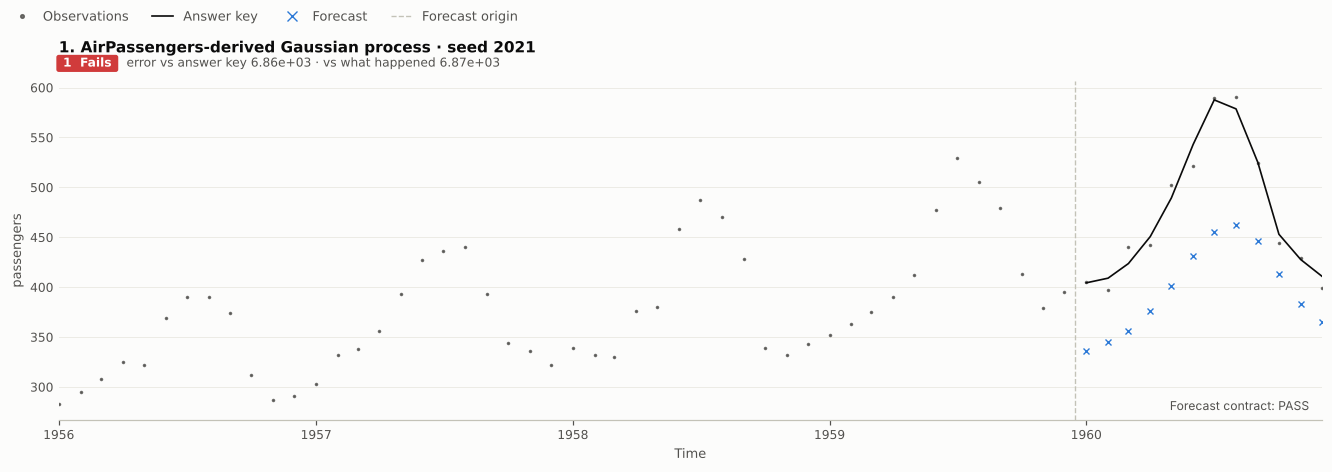

In [9]:
truth_curve = series.rolling(window=3, center=True, min_periods=1).mean()


def truth(index):
    return truth_curve.loc[index].copy()


noise_sd = 10.0
semi_seed = 2021
rng = np.random.default_rng(semi_seed)
semi_observed = truth(series.index) + rng.normal(0.0, noise_sd, size=series.shape)
semi_task = ForecastTask(semi_observed.iloc[:origin].copy(), series.index[origin:].copy())
known_reference = Reference.from_function(
    truth, semi_task.future_index,
    covariance=noise_sd**2 * np.eye(len(semi_task.future_index)),
    target_names=semi_task.target_names,
    conditioning={"source_sha256": source_sha256,
                  "truth": "fixed centered 3-month mean, min_periods=1",
                  "noise": "independent Gaussian", "noise_sd": noise_sd},
)
semi_case = Case(semi_task, semi_observed.iloc[origin:].copy(), known_reference,
                 {"kind": "AirPassengers-derived Gaussian process", "seed": semi_seed,
                  "context_length": origin, "horizon": len(semi_task.future_index),
                  "reference_kind": known_reference.kind,
                  "reference_conditioning": known_reference.conditioning})
semi_forecast = point_prediction(semi_task)
semi_result = evaluate_forecast(semi_case, semi_forecast, check_dependence=True)
assert semi_forecast.validate(semi_task) == []
np.testing.assert_allclose(known_reference.mean, truth(semi_task.future_index).to_numpy())
np.testing.assert_allclose(known_reference.variance, noise_sd**2)
assert "mean_reference_mse" in semi_result.metrics
assert next(d.status for d in semi_result.diagnostics
            if d.name == "reference_covariance") == "UNSUPPORTED"
semi_run = ForecastRun([EvaluatedCase(semi_case, semi_forecast, semi_result, 0, 0)])
fig = plot_contracts(semi_run, figsize=(12, 4.2))
plt.show()

The semi-synthetic plot now has a known-mean curve. Its squared discrepancy from the blue crosses can be separated from the noise in held-out observations. The covariance comparison still remains `UNSUPPORTED` because we supplied only forecast points, even though a reference covariance is now known. Adding evaluator knowledge does not manufacture a model's uncertainty output.

In [10]:
comparison = pd.DataFrame([
    {"data": "Historical observations", "reference": "unavailable", **real_result.metrics},
    {"data": "Semi-synthetic observations", "reference": known_reference.kind, **semi_result.metrics},
]).set_index("data")
display(comparison.round(3))
print("The missing reference score is unavailable, not zero; these rows use different observations.")

,reference,mse,mae,mase,mean_reference_mse
data,,,,,
Historical observations,unavailable,7801.949,78.781,3.271,NaN
Semi-synthetic observations,user_supplied_gaussian,6867.509,76.358,4.120,6859.447


The missing reference score is unavailable, not zero; these rows use different observations.


### Retain settings and the construction recipe

Custom Python classes and truth functions are not reconstructed by automatic report replay. Keep this notebook with the data checksum, model settings, origin, noise seed, and environment. Re-running it regenerates the controlled examples. The report stores scores and metadata; it does not embed the complete data or callable code.

In [11]:
from timegym import TestReport

assert pipeline.to_config()["replayable"] is False
report = TestReport(cases=[real_result, semi_result], metadata={
    "model": "NearestAnalogues", "model_parameters": pipeline.model.params(),
    "pipeline_config": pipeline.to_config(), "source_sha256": source_sha256,
    "origin_length": origin, "semi_seed": semi_seed,
    "reference_conditioning": known_reference.conditioning,
    "numpy": np.__version__, "pandas": pd.__version__, "timegym": timegym.__version__,
    "automatic_replay_supported": False,
    "reproduction": "Run notebooks/28_custom_model.ipynb with the bundled AirPassengers CSV.",
})
serialized = report.to_json()
assert json.loads(serialized)["summary"]["cases"] == 2
display(pd.Series(report.summary, name="Real and semi-synthetic report"))

cases                                                            2
diagnostics                                                     10
status_counts    {'PASS': 2, 'FAIL': 0, 'INCONCLUSIVE': 2, 'UNS...
failed_cases                                                     0
Name: Real and semi-synthetic report, dtype: object

## Change one thing

- Change `k` or the window length before inspecting a fresh holdout. More neighbours alter both smoothing and the empirical paths.
- Compare raw-value matching with context-only level alignment. Check whether the change helps trends without harming seasonal or noise cases.
- Replace `NearestAnalogues` with your own `fit(context)` and `predict(future_index)`. Preserve target order and return a `Forecast` with explicit point, quantile, or joint-sample outputs.
- Supply another known Gaussian truth function with its covariance. Keep evaluator knowledge out of the model, and use new independent noise realizations for controlled replications.

**Scope.** Historical analogues are dependent empirical paths. The real-data example has one holdout, and the semi-synthetic reference describes a declared constructed process. This notebook revives the 2021 figure's comparison, not its original implementation or empirical results.

Continue with [univariate uncertainty](20_univariate_uncertainty.ipynb) to evaluate intervals across independent cases, or [faults, repairs, and replay](23_faults_repairs_and_replay.ipynb) to inspect other contract failures.